# 01 — Exploratory data analysis

What the credit-card data looks like before we model it. The notebook loads the data and removes
duplicate rows with `fraudstudy.data` (the same code the experiment uses), draws the EDA figures
into `artifacts/figures/eda_*.png` and writes `artifacts/metrics/eda_summary.json` for the results notebook.

Everything here is descriptive: no model setting, ratio or threshold is chosen from these plots
(those come from cross-validation on the training rows only). Run it from the repository root
environment after `pip install -r requirements.txt` (it installs Jupyter too).

## Setup
Import the libraries and our own data functions, and pick the data source. `SOURCE = "sample"`
runs the notebook on the small fake copy and writes to `artifacts/sample/`, so a trial never
overwrites the real figures.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraudstudy.data import load_data, remove_duplicates, split_data
from fraudstudy.experiments import artifacts_dir

SOURCE = "raw"  # "raw" = data/raw/creditcard.csv, "sample" = the fake copy in data/sample/
FIGURES_DIR = artifacts_dir(SOURCE) / "figures"
METRICS_DIR = artifacts_dir(SOURCE) / "metrics"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
LEGIT_COLOUR, FRAUD_COLOUR = "#0072B2", "#D55E00"  # blue and orange, safe for colour-blind readers

## 1. Dataset size and fraud rate
Load the CSV with `load_data`, which also checks that all 31 columns are there, and count rows,
frauds and missing values. The fraud rate tells us how imbalanced the problem is.

In [2]:
raw = load_data(SOURCE)
rows, frauds = len(raw), int(raw["Class"].sum())
print(f"rows:           {rows:,} ({raw.shape[1]} columns)")
print(f"frauds:         {frauds:,}")
print(f"fraud rate:     {frauds / rows:.4%}  (1 fraud for every {round((rows - frauds) / frauds)} legit payments)")
print(f"missing values: {int(raw.isna().sum().sum())}")

rows:           284,807 (31 columns)
frauds:         492
fraud rate:     0.1727%  (1 fraud for every 578 legit payments)
missing values: 0


Remove exact duplicate rows (section 7 says why) and keep the cleaned table `df` for every
plot below. `legit` and `fraud` are the two classes of that table.

In [3]:
df, duplicates_removed, duplicate_frauds = remove_duplicates(raw)
legit, fraud = df[df["Class"] == 0], df[df["Class"] == 1]
print(f"after removing duplicates: {len(df):,} rows, {len(fraud):,} frauds")

after removing duplicates: 283,726 rows, 473 frauds


## 2. Class counts on a linear and a log scale
The same two bars twice: on a normal axis the fraud bar is almost invisible, on a log axis both
can be read. The last line shows why accuracy is useless here: always answering "legit" already
scores this high.

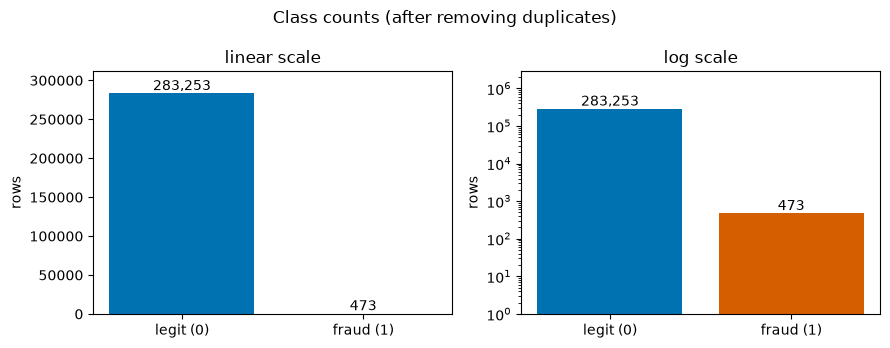

accuracy of always answering 'legit': 99.8333%


In [4]:
counts = [len(legit), len(fraud)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.bar(["legit (0)", "fraud (1)"], counts, color=[LEGIT_COLOUR, FRAUD_COLOUR])
    ax.set(yscale=scale, title=f"{scale} scale", ylabel="rows")
    for x, n in enumerate(counts):
        ax.text(x, n, f"{n:,}", ha="center", va="bottom")
axes[0].set_ylim(0, 1.1 * len(legit))  # room for the number on top of the bar
axes[1].set_ylim(1, 10 * len(legit))  # a log axis that starts at 1 keeps the fraud bar honest
fig.suptitle("Class counts (after removing duplicates)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_class_counts_linear_vs_log.png", dpi=150)
plt.show()
print(f"accuracy of always answering 'legit': {len(legit) / len(df):.4%}")

## 3. Amount: raw vs log1p
Histograms of the payment amount before and after `log1p` (log(1 + x), which also works for an
amount of 0). Raw amounts are very skewed, with a few huge payments; log1p spreads them out, which
is why our preprocessing applies it before scaling.

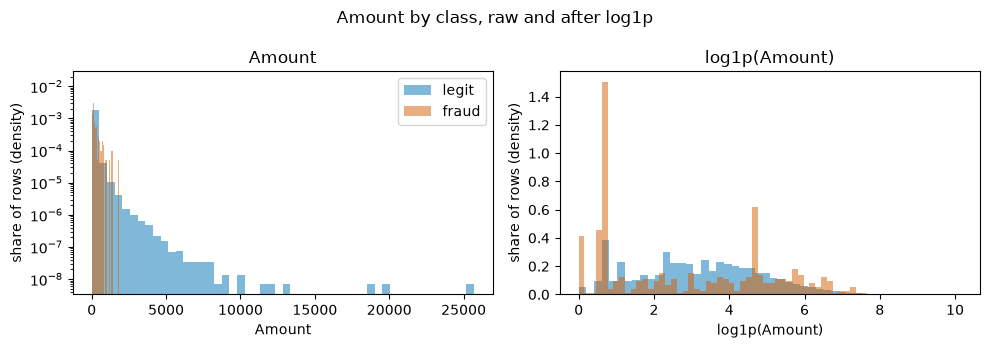

skewness raw: 17.0, after log1p: 0.16
median amount legit: 22.00, fraud: 9.82


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, transform, name in [(axes[0], np.asarray, "Amount"), (axes[1], np.log1p, "log1p(Amount)")]:
    for group, colour, label in [(legit, LEGIT_COLOUR, "legit"), (fraud, FRAUD_COLOUR, "fraud")]:
        ax.hist(transform(group["Amount"]), bins=50, density=True, alpha=0.5, color=colour,
                label=label)
    ax.set(title=name, xlabel=name, ylabel="share of rows (density)")
axes[0].set_yscale("log")  # without it the raw panel is one tall bar near 0
axes[0].legend()
fig.suptitle("Amount by class, raw and after log1p")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_amount_raw_vs_log.png", dpi=150)
plt.show()
print(f"skewness raw: {df['Amount'].skew():.1f}, after log1p: {np.log1p(df['Amount']).skew():.2f}")
print(f"median amount legit: {legit['Amount'].median():.2f}, fraud: {fraud['Amount'].median():.2f}")

## 4. Time, and why it is not a model feature
`Time` counts seconds from the first payment in the file, so we plot it in hours, per class. It
only says when in this two-day window a payment happened: a new payment would have a Time outside
this range, so `split_data` drops it and the models never see it.

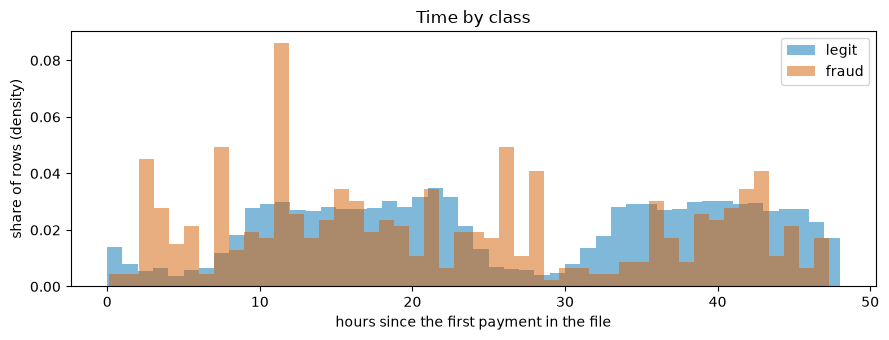

the data covers 48.0 hours


In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for group, colour, label in [(legit, LEGIT_COLOUR, "legit"), (fraud, FRAUD_COLOUR, "fraud")]:
    ax.hist(group["Time"] / 3600, bins=48, density=True, alpha=0.5, color=colour, label=label)
ax.set(xlabel="hours since the first payment in the file", ylabel="share of rows (density)",
       title="Time by class")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_time_by_class.png", dpi=150)
plt.show()
print(f"the data covers {df['Time'].max() / 3600:.1f} hours")

## 5. Effect sizes (Cohen's d)
Cohen's d is the difference between the fraud mean and the legit mean, divided by the pooled
standard deviation, so every feature is measured in the same "number of standard deviations" unit.
We compute it for the 29 columns the model sees (V1..V28 and log1p of Amount); about 0.2 is small,
0.8 large.

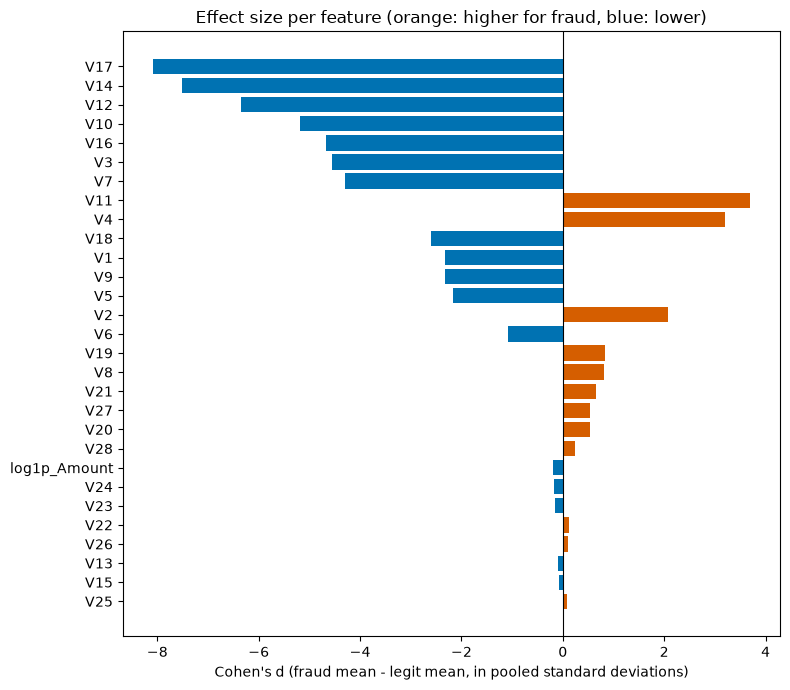

V17   -8.09
V14   -7.52
V12   -6.35
V10   -5.19
V16   -4.67
V3    -4.55
V7    -4.29
V11    3.70
V4     3.20
V18   -2.60
dtype: float64

In [7]:
def cohens_d(a: pd.Series, b: pd.Series) -> float:
    """(mean of a - mean of b) / pooled standard deviation of a and b."""
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled


features = df.drop(columns=["Time", "Class"])
features["Amount"] = np.log1p(features["Amount"])
features = features.rename(columns={"Amount": "log1p_Amount"})
is_fraud = df["Class"] == 1
effect = pd.Series({column: cohens_d(features.loc[is_fraud, column], features.loc[~is_fraud, column])
                    for column in features.columns})
effect = effect[effect.abs().sort_values(ascending=False).index]  # biggest difference first

fig, ax = plt.subplots(figsize=(8, 7))
colours = [FRAUD_COLOUR if d > 0 else LEGIT_COLOUR for d in effect]
ax.barh(effect.index[::-1], effect.values[::-1], color=colours[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Cohen's d (fraud mean - legit mean, in pooled standard deviations)",
       title="Effect size per feature (orange: higher for fraud, blue: lower)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_effect_sizes.png", dpi=150)
plt.show()
effect.head(10).round(2)

## 6. The top 6 features by class
Histograms of the 6 features with the largest |d|, legit and fraud on the same bins. Densities
(not counts) are drawn, otherwise the small fraud class would be a flat line. The bins cover the
middle 99% of each class, so a handful of extreme values do not squash the picture.

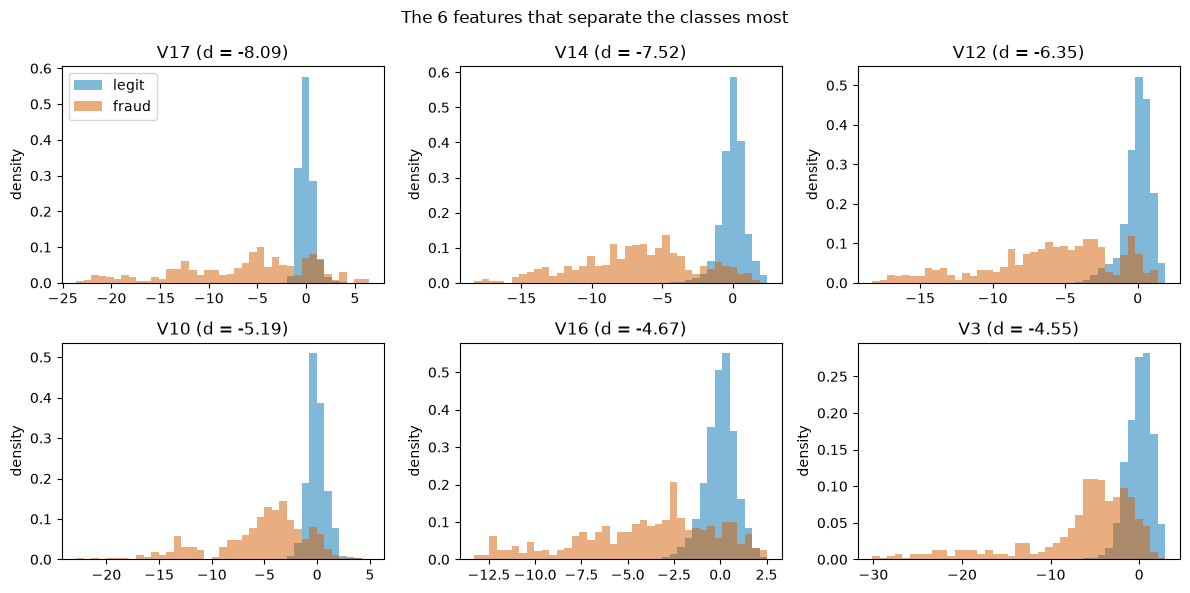

In [8]:
top6 = list(effect.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, column in zip(axes.ravel(), top6):
    values = features[column]
    low = min(values[~is_fraud].quantile(0.005), values[is_fraud].quantile(0.005))
    high = max(values[~is_fraud].quantile(0.995), values[is_fraud].quantile(0.995))
    bins = np.linspace(low, high, 40)
    ax.hist(values[~is_fraud], bins=bins, density=True, alpha=0.5, color=LEGIT_COLOUR, label="legit")
    ax.hist(values[is_fraud], bins=bins, density=True, alpha=0.5, color=FRAUD_COLOUR, label="fraud")
    ax.set(title=f"{column} (d = {effect[column]:.2f})", ylabel="density")
axes[0, 0].legend()
fig.suptitle("The 6 features that separate the classes most")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_top_features_by_class.png", dpi=150)
plt.show()

## 7. Duplicates
How many exact copies `remove_duplicates` dropped. We remove them because one copy could land in
the training set and the other in the test set, and the model would then be tested on a row it
was trained on.

In [9]:
print(f"duplicate rows removed: {duplicates_removed:,} ({duplicates_removed / rows:.2%} of the rows)")
print(f"frauds among them:     {duplicate_frauds}")
print(f"rows left:             {len(df):,}, frauds left: {len(fraud):,} ({len(fraud) / len(df):.4%})")

duplicate rows removed: 1,081 (0.38% of the rows)
frauds among them:     19
rows left:             283,726, frauds left: 473 (0.1667%)


## Save the summary for the results notebook
Split with `split_data` (stratified 70/30 with the project seed) only to record the two sizes, and
save the main numbers to `eda_summary.json`. Nothing here looks at the test rows' values.

In [10]:
X_train, X_test, y_train, y_test = split_data(df)
summary = {
    "rows": rows,
    "frauds": frauds,
    "fraud_rate": frauds / rows,
    "duplicates_removed": duplicates_removed,
    "train_rows": len(y_train),
    "test_rows": len(y_test),
}
(METRICS_DIR / "eda_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print(f"train frauds: {int(y_train.sum())}, test frauds: {int(y_test.sum())}")

{
  "rows": 284807,
  "frauds": 492,
  "fraud_rate": 0.001727485630620034,
  "duplicates_removed": 1081,
  "train_rows": 198608,
  "test_rows": 85118
}
train frauds: 331, test frauds: 142


## What we take away (numbers from the real data)
- 284,807 rows and 492 frauds (0.173%, 1 fraud per 578 legit payments). After removing 1,081
  duplicate rows (19 of them frauds): 283,726 rows and 473 frauds. Always answering "legit" is
  99.83% accurate and catches no fraud, so we judge models by PR-AUC, never accuracy.
- Amount is very skewed (skewness 17.0) and log1p brings that down to 0.16, so the preprocessing
  uses log1p(Amount) before the RobustScaler. On its own, log1p(Amount) barely separates the
  classes (d = -0.2).
- Time covers 48 hours; legit payments drop at night and frauds do not follow that pattern as
  closely. It describes this particular two-day file, so it is not a model feature.
- Several PCA features separate the classes strongly: V17, V14, V12 and V10 have |d| above 5
  (lower for fraud), V11 and V4 are higher for fraud. Fraud values are spread out with long tails,
  which is why we keep outliers: they are often the frauds.
- The 70/30 stratified split gives 198,608 training rows (331 frauds) and 85,118 test rows
  (142 frauds).
